# Line fitting the matrix way
This in-class exercise walks you through the following steps to fit a line to several datasets:
1. Create the datasets.
2. Construct design matrices.
3. Compute the weights using matrix inversion.
4. Plot the data and the fitted line.

## Linear (line) models

---
**Task 1 (easy): Identifying parameters👩‍💻**
1. Run the cell below to load the neccessary libraries and to construct the datasets.

2. Identify the inputs and the labels of each dataset. 



---

In [1]:
import numpy as np
import matplotlib.pyplot as plt

dataset_1 = np.array([[10, 2], [9, 6]]) # (x,y), (x,y)
dataset_2 = np.array([[5, 1], [7, 5]]) # (x,y), (x,y)
dataset_3 = np.array([[4, 2], [5, 3]]) # (x,y), (x,y)


---
**Task 2 (easy): Identifying parameters and constructing the design matrix👩‍💻**
1. Complete the `separate_inputs_labels`
 function below. The function should take a dataset as input and return the inputs and labels separated into separate variables. The function should return a matrix `X`
 containing the inputs and an array `y`
 containing the labels. Use the function to obtain the inputs and labels for each dataset.


**Hint**
Slicing might be helpful here.

2. Complete the code below and construct the design matrix for the other datasets. Print your results.


---

In [2]:
def separate_inputs_labels(dataset):
    """
    This function takes a dataset as input and returns the inputs and labels.
    
    Parameters:
    dataset (numpy array): The dataset to be separated.
    
    Returns:
    X (numpy array): The input matrix.
    y (numpy array): The labels array.
    """
    X = dataset[:,0] # first column
    y = dataset[:,1] # second column
        
    # return the results as a tuple
    return X, y

# construct the design matrix 
# first column = input, 
# second column = 1s, 
X1, y1 = separate_inputs_labels(dataset_1)   
X1_design =  np.column_stack((X1, np.ones(X1.shape[0])))
X2, y2 = separate_inputs_labels(dataset_2)
X2_design =  np.column_stack((X2, np.ones(X2.shape[0])))
X3, y3 = separate_inputs_labels(dataset_3)
X3_design =  np.column_stack((X3, np.ones(X3.shape[0])))

# Print the datasets
print("X1 = \n",X1)
print("y1 =", y1)
print("Design Matrix for Dataset 1:\n", X1_design)
print("\nX2 = \n",X2)
print("y2 =", y2)
print("Design Matrix for Dataset 2:\n", X2_design)
print("\nX3 = \n",X3)
print("y3 =", y3)
print("Design Matrix for Dataset 3:\n", X3_design)


X1 = 
 [10  9]
y1 = [2 6]
Design Matrix for Dataset 1:
 [[10.  1.]
 [ 9.  1.]]

X2 = 
 [5 7]
y2 = [1 5]
Design Matrix for Dataset 2:
 [[5. 1.]
 [7. 1.]]

X3 = 
 [4 5]
y3 = [2 3]
Design Matrix for Dataset 3:
 [[4. 1.]
 [5. 1.]]



---
**Task 3 (easy): Solve for model parameters👩‍💻**
1. Find the inverse of the design matrix for each dataset constructed above.
2. Calculate the model weights, then print your results.
3. Use the `plot_model`
 function to plot your results.
4. Visually inspect the plots and interpret the meaning and influence of each term.


---

Weights for Dataset 1: [-4. 42.]
Weights for Dataset 2: [ 2. -9.]
Weights for Dataset 3: [ 1. -2.]


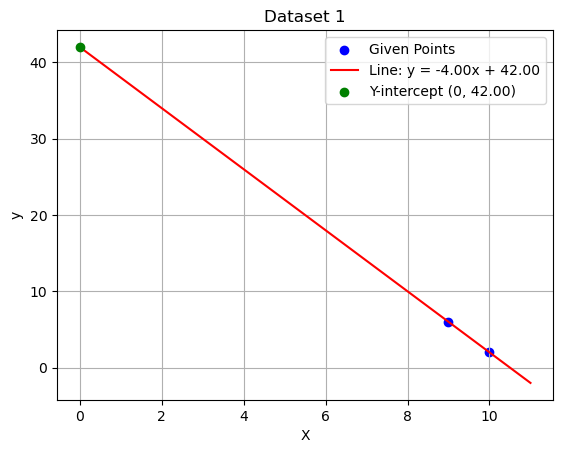

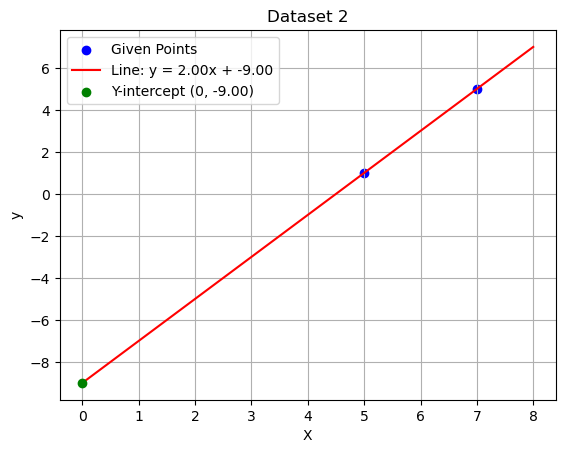

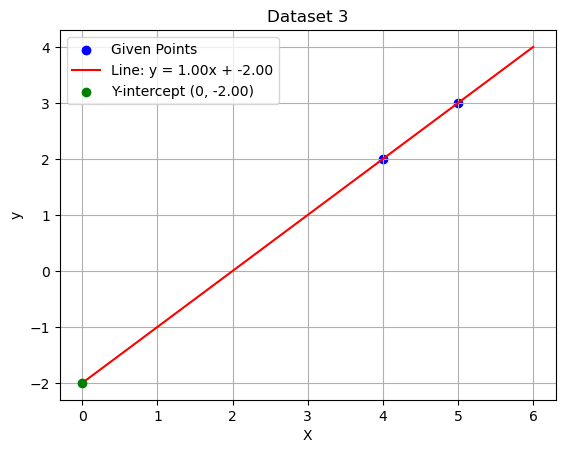

In [5]:
# w = A^-1 * b
A_inv = np.linalg.inv(X1_design)
A_weights = A_inv @ y1 
B_inv = np.linalg.inv(X2_design)
B_weights = B_inv @ y2 
C_inv = np.linalg.inv(X3_design)
C_weights = C_inv @ y3


print("Weights for Dataset 1:", A_weights)
print("Weights for Dataset 2:", B_weights)
print("Weights for Dataset 3:", C_weights)

# Function to plot data points and fitted line
def plot_model(X, y, wieghts, dataset_name):
    # Plot the data points
    plt.scatter(X, y, color='blue', label='Given Points')
    
    # Extend x_vals range to include zero for correct y-intercept visualization
    x_vals = np.linspace(0, max(X) + 1, 100)
    y_vals = wieghts[0] * x_vals + wieghts[1]
    
    # Plot the fitted line
    plt.plot(x_vals, y_vals, color='red', label=f'Line: y = {wieghts[0]:.2f}x + {wieghts[1]:.2f}')
    
    # Plot the y-intercept
    plt.scatter(0, wieghts[1], color='green', zorder=5, label=f'Y-intercept (0, {wieghts[1]:.2f})')
    
    # Add title and labels
    plt.title(dataset_name)
    plt.xlabel('X')
    plt.ylabel('y')
    plt.legend()
    plt.grid(True)
    plt.show()
    

plot_model(X1, y1, A_weights, 'Dataset 1')
plot_model(X2, y2, B_weights, 'Dataset 2')
plot_model(X3, y3, C_weights, 'Dataset 3')

If you have more time, complete the next task.

---
**Task 4 (easy): A new dataset👩‍💻♾️💡**
Run the cell below to define a new dataset.
1. Identify the inputs and the labels, then reuse the code from previous tasks to construct a design matrix.
2. Calculate the inverse of the design matrix. This step should result in an error. What are the possible reasons for getting this error?

**Note:** For pedagogical reasons, next week we will return to this dataset, as you will have the necessary tools to fit a model for this scenario.


---

In [4]:
dataset_4 = np.array([[9, 1], [7, 2],[3, 8], [1, 3],[4, 3]])